# 09. Curvas anytime y multi-fidelidad

La tabla maestra guarda el resultado final de cada búsqueda, pero no dice qué tan rápido encontró un buen candidato. Este notebook corrige esa omisión de dos maneras:

1. **Curvas anytime** de los cuatro optimizadores del proyecto (grid, random, bayesiana con TPE y genético con DEAP): calidad del mejor candidato encontrado si la búsqueda se detuviera en cada punto, medida en número de evaluaciones y en costo de cómputo.
2. **Multi-fidelidad**: se implementó Hyperband desde cero (`src/multifidelity.py`), usando como fidelidad la fracción de filas de entrenamiento, y se compara con Random Search sobre el mismo espacio de búsqueda.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)  # nanmedian sobre tramos sin datos

from src import config
from src.anytime_study import load_anytime_results, METHODS

config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
traces, finals = load_anytime_results()
print(f"{traces.groupby(['model', 'fold', 'method']).ngroups} corridas, "
      f"{finals['model'].nunique()} modelos, folds {sorted(finals['fold'].unique())}, "
      f"semillas {sorted(finals['seed'].unique())}")
finals.groupby(["model", "method"]).size().unstack()

45 corridas, 3 modelos, folds [np.int64(0), np.int64(1), np.int64(2)], semillas [np.int64(42)]


C:\Users\valef\anaconda3\envs\creditcard\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


method,bayesian_optuna,genetic_deap,grid_search,hyperband,random_search
model,,,,,
decision_tree,3,3,3,3,3
logistic_regression,3,3,3,3,3
xgboost,3,3,3,3,3


**Diseño del estudio** (`src/anytime_study.py`).
- Tres modelos: regresión logística, árbol de decisión y XGBoost, con `class_weight`. Se eligieron los más baratos de cada familia para poder repetir las búsquedas completas; no se corrió con Random Forest, KNN, Naive Bayes ni SVM.
- Los mismos 3 folds externos del protocolo (`StratifiedKFold(3, shuffle=True, random_state=42)`) y los mismos 3 folds internos. La optimización solo ve el fold de entrenamiento externo. El fold de prueba se usa una sola vez al final, para el F1 externo del candidato elegido.
- Los presupuestos son los de `src/config.py`: Random 25 configuraciones, TPE 30 ensayos, genético con población 16 y 10 generaciones (el número de evaluaciones distintas es menor, porque los individuos que no cambian no se reevalúan) y grid con la grilla de cada modelo (8, 128 y 64 puntos). Hyperband usa `eta = 3`, fidelidad mínima 1/9 y 3 repeticiones del ciclo de brackets.
- Una sola semilla (42). Las 45 corridas son 3 modelos por 3 folds por 5 métodos.
- **Costo.** Se mide como la suma de las duraciones de cada evaluación (costo secuencial equivalente), que no depende del paralelismo.
- **Arrepentimiento.** Para cada modelo y fold, diferencia entre el mejor score interno visto por cualquier método a fidelidad completa y el mejor score del método hasta ese punto. Los scores son de validación interna, la misma que ve el optimizador.

## 1. Curvas anytime: arrepentimiento frente al número de evaluaciones

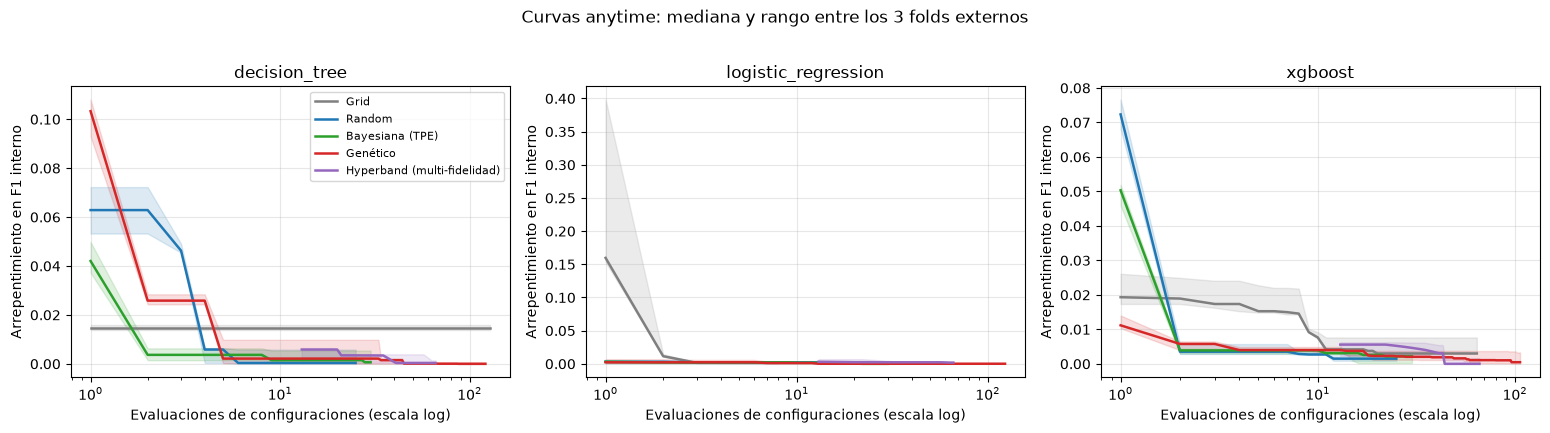

In [2]:
COLORS = {
    "grid_search": "#7f7f7f", "random_search": "#1f77b4", "bayesian_optuna": "#2ca02c",
    "genetic_deap": "#d62728", "hyperband": "#9467bd",
}
LABELS = {
    "grid_search": "Grid", "random_search": "Random", "bayesian_optuna": "Bayesiana (TPE)",
    "genetic_deap": "Genético", "hyperband": "Hyperband (multi-fidelidad)",
}
models = sorted(traces["model"].unique())

# Referencia por (modelo, fold): el mejor score interno visto por CUALQUIER método
# a fidelidad completa. Arrepentimiento = referencia - mejor score hasta ese momento.
full = traces[traces["fidelity"] >= 1.0]
reference = full.groupby(["model", "fold"])["score"].max().rename("reference")
traces = traces.merge(reference, on=["model", "fold"])
traces["regret"] = traces["reference"] - traces["best_so_far"]


def median_curve(df, x_col, grid):
    """Mediana (y rango min-max) entre folds de la curva regret(x), evaluada en ``grid``.

    Cada corrida se lleva a una malla común con la última observación disponible
    (``best_so_far`` es una función escalonada); antes de su primera observación
    válida la curva no existe (NaN) y no se dibuja.
    """
    curves = []
    for _, run in df.groupby(["fold", "seed"]):
        run = run.dropna(subset=["regret"]).sort_values(x_col)
        if run.empty:
            continue
        values = np.interp(grid, run[x_col], run["regret"], left=np.nan)
        curves.append(values)
    arr = np.array(curves)
    return np.nanmedian(arr, axis=0), np.nanmin(arr, axis=0), np.nanmax(arr, axis=0)


fig, axes = plt.subplots(1, len(models), figsize=(5.2 * len(models), 4.2), sharey=False)
axes = np.atleast_1d(axes)
for ax, model in zip(axes, models):
    sub = traces[traces["model"] == model]
    grid = np.arange(1, int(sub["eval"].max()) + 1)
    for method in METHODS:
        run = sub[sub["method"] == method]
        if run.empty:
            continue
        med, lo, hi = median_curve(run, "eval", grid)
        last = int(run["eval"].max())
        ax.plot(grid[:last], med[:last], color=COLORS[method], label=LABELS[method], lw=1.8)
        ax.fill_between(grid[:last], lo[:last], hi[:last], color=COLORS[method], alpha=0.15)
    ax.set_xscale("log")
    ax.set_title(model)
    ax.set_xlabel("Evaluaciones de configuraciones (escala log)")
    ax.set_ylabel("Arrepentimiento en F1 interno")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle("Curvas anytime: mediana y rango entre los 3 folds externos", y=1.02)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "anytime_vs_evaluations.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura.**
- **Regresión logística.** Todos los métodos llegan casi de inmediato a un arrepentimiento cercano a cero, porque el espacio de búsqueda es pequeño y la superficie es plana. Solo grid parte de un punto malo, porque sus primeras configuraciones son malas.
- **Árbol de decisión.** Aquí hay diferencias. TPE es el que más rápido baja en pocas evaluaciones. Random y el genético empiezan peor y necesitan entre 5 y 10 evaluaciones. **Grid no llega nunca**: su arrepentimiento se queda en cerca de 0.015 porque su grilla fija no contiene configuraciones tan buenas como las que encuentran los otros métodos, y es la única búsqueda que termina claramente por debajo de las demás en F1 externo (0.510 contra 0.515 a 0.519).
- **XGBoost.** El genético arranca mejor (probablemente porque su población inicial de 16 individuos incluye algún punto bueno), pero después avanza poco. Random y TPE parten de un arrepentimiento alto y lo corrigen entre las evaluaciones 5 y 15.
- En ningún modelo la ventaja de un método sobre otro persiste hasta el final: al agotar el presupuesto el arrepentimiento está por debajo de 0.004 en todos salvo grid en el árbol.

## 2. Curvas anytime frente al costo de cómputo

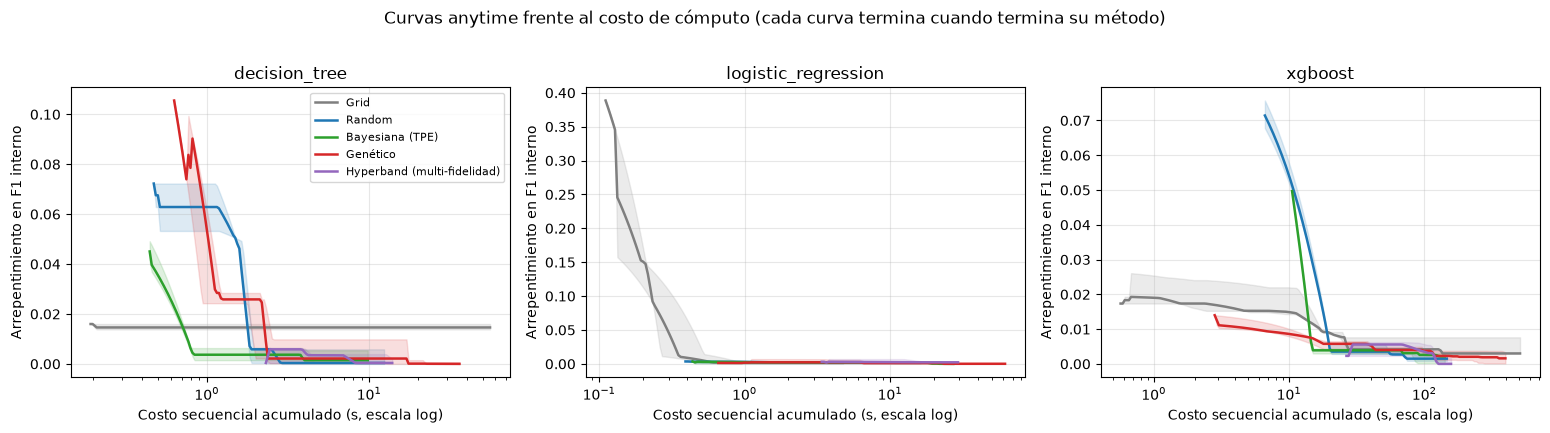

In [3]:
fig, axes = plt.subplots(1, len(models), figsize=(5.2 * len(models), 4.2), sharey=False)
axes = np.atleast_1d(axes)
for ax, model in zip(axes, models):
    sub = traces[traces["model"] == model]
    grid = np.logspace(np.log10(max(sub["cum_cost_seconds"].min(), 0.1)), np.log10(sub["cum_cost_seconds"].max()), 200)
    for method in METHODS:
        run = sub[sub["method"] == method]
        if run.empty:
            continue
        med, lo, hi = median_curve(run, "cum_cost_seconds", grid)
        end = run.groupby(["fold", "seed"])["cum_cost_seconds"].max().min()
        keep = grid <= end
        ax.plot(grid[keep], med[keep], color=COLORS[method], label=LABELS[method], lw=1.8)
        ax.fill_between(grid[keep], lo[keep], hi[keep], color=COLORS[method], alpha=0.15)
    ax.set_xscale("log")
    ax.set_title(model)
    ax.set_xlabel("Costo secuencial acumulado (s, escala log)")
    ax.set_ylabel("Arrepentimiento en F1 interno")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle("Curvas anytime frente al costo de cómputo (cada curva termina cuando termina su método)", y=1.02)
fig.tight_layout()
fig.savefig(config.FIGURES_DIR / "anytime_vs_cost.png", dpi=150, bbox_inches="tight")
plt.show()

**Lectura.** Al medir el costo en segundos el panorama cambia respecto al número de evaluaciones.
- El genético es el que más evaluaciones usa (entre 106 y 123), y en XGBoost su costo (522 s) es unas 3.5 veces el de Random (150 s) para un F1 externo igual (0.544 contra 0.544). Grid en XGBoost cuesta lo mismo que el genético (518 s) y no mejora nada.
- Random y TPE son las opciones con mejor relación entre costo y calidad: en XGBoost alcanzan el mismo F1 externo (0.544 y 0.545) con menos de un tercio del costo.
- Esto es coherente con lo visto en la tabla maestra, donde los cuatro optimizadores son equivalentes en métrica: aquí se ve que lo que los distingue es el costo para llegar ahí, no el punto de llegada.

## 3. Resumen: costo para acercarse al mejor score y desempeño en el fold externo

In [4]:
EPS = 0.002  # "cerca del mejor": a menos de 0.002 de F1 interno de la referencia


def cost_to_target(run):
    reached = run[run["regret"] <= EPS]
    return reached["cum_cost_seconds"].min() if not reached.empty else np.nan


def evals_to_target(run):
    reached = run[run["regret"] <= EPS]
    return reached["eval"].min() if not reached.empty else np.nan


rows = []
for (model, fold, seed, method), run in traces.groupby(["model", "fold", "seed", "method"]):
    rows.append({
        "model": model, "fold": fold, "seed": seed, "method": method,
        "cost_to_target_s": cost_to_target(run), "evals_to_target": evals_to_target(run),
        "final_regret": run.sort_values("eval")["regret"].iloc[-1],
    })
summary = pd.DataFrame(rows).merge(
    finals[["model", "fold", "seed", "method", "n_evaluations", "total_cost_seconds", "outer_f1", "outer_roc_auc"]],
    on=["model", "fold", "seed", "method"],
)
table = (
    summary.groupby(["model", "method"])
    .agg(
        evaluaciones=("n_evaluations", "mean"),
        costo_total_s=("total_cost_seconds", "mean"),
        costo_hasta_objetivo_s=("cost_to_target_s", "median"),
        corridas_que_llegan=("cost_to_target_s", lambda s: int(s.notna().sum())),
        arrepentimiento_final=("final_regret", "mean"),
        f1_externo_media=("outer_f1", "mean"),
        f1_externo_std=("outer_f1", lambda s: s.std(ddof=1)),
    )
    .round(4)
)
table

evaluaciones  costo_total_s  \
model               method                                         
decision_tree       bayesian_optuna          30.0        11.6369   
                    genetic_deap            121.0        42.6987   
                    grid_search             128.0        58.1370   
                    hyperband                66.0        14.6332   
                    random_search            25.0        12.7179   
logistic_regression bayesian_optuna          30.0        28.2791   
                    genetic_deap            123.0       102.4710   
                    grid_search               8.0         8.4123   
                    hyperband                66.0        35.1722   
                    random_search            25.0        22.9455   
xgboost             bayesian_optuna          30.0       159.3866   
                    genetic_deap            106.0       521.9567   
                    grid_search              64.0       517.7790   
                    hyperband                66.0       166.3828   
                    random_search            25.0       149.5578   

                                     costo_hasta_objetivo_s  \
model               method                                    
decision_tree       bayesian_optuna                  2.4125   
                    genetic_deap                    17.4236   
                    grid_search                         NaN   
                    hyperband                        8.2842   
                    random_search                    2.3528   
logistic_regression bayesian_optuna                 17.5038   
                    genetic_deap                     6.6330   
                    grid_search                      0.6973   
                    hyperband                       18.4666   
                    random_search                    6.9596   
xgboost             bayesian_optuna                 84.1071   
                    genetic_deap                   190.3994   
                    grid_search                         NaN   
                    hyperband                      123.6289   
                    random_search                   74.0071   

                                     corridas_que_llegan  \
model               method                                 
decision_tree       bayesian_optuna                    2   
                    genetic_deap                       3   
                    grid_search                        0   
                    hyperband                          3   
                    random_search                      2   
logistic_regression bayesian_optuna                    3   
                    genetic_deap                       3   
                    grid_search                        3   
                    hyperband                          2   
                    random_search                      2   
xgboost             bayesian_optuna                    1   
                    genetic_deap                       2   
                    grid_search                        0   
                    hyperband                          3   
                    random_search                      2   

                                     arrepentimiento_final  f1_externo_media  \
model               method                                                     
decision_tree       bayesian_optuna                 0.0021            0.5176   
                    genetic_deap                    0.0002            0.5190   
                    grid_search                     0.0148            0.5100   
                    hyperband                       0.0006            0.5185   
                    random_search                   0.0021            0.5152   
logistic_regression bayesian_optuna                 0.0001            0.5148   
                    genetic_deap                    0.0004            0.5146   
                    grid_search                     0.0014         

**Lectura.** La columna `costo_hasta_objetivo_s` es la mediana del costo acumulado hasta quedar a menos de 0.002 de F1 interno de la referencia, y `corridas_que_llegan` dice en cuántos de los 3 folds se logra (cuando es 0 la mediana está vacía). Ninguna corrida de grid llega en el árbol de decisión ni en XGBoost. En XGBoost, Random llega en 74 s (2 de 3 folds), Hyperband en 124 s (3 de 3), TPE en 84 s (1 de 3) y el genético en 190 s (2 de 3). Con 3 folds estos tiempos son indicativos, no concluyentes.

El F1 externo medio es prácticamente el mismo entre métodos dentro de cada modelo (por ejemplo, en XGBoost va de 0.544 a 0.547, con desviación entre folds de 0.006 a 0.013). Se confirma, sobre un fold de prueba que no usó la optimización, que el método de búsqueda no cambia el desempeño final.

## 4. Multi-fidelidad: Hyperband frente a Random Search con un costo comparable

In [5]:
pair = finals[finals["method"].isin(["random_search", "hyperband"])].pivot_table(
    index=["model", "fold", "seed"], columns="method",
    values=["outer_f1", "total_cost_seconds", "inner_best_score"],
)
comp = pd.DataFrame({
    "F1 externo random": pair[("outer_f1", "random_search")],
    "F1 externo hyperband": pair[("outer_f1", "hyperband")],
    "dif. F1 (hyperband - random)": pair[("outer_f1", "hyperband")] - pair[("outer_f1", "random_search")],
    "costo random (s)": pair[("total_cost_seconds", "random_search")],
    "costo hyperband (s)": pair[("total_cost_seconds", "hyperband")],
})
comp["razón de costo (hyperband/random)"] = comp["costo hyperband (s)"] / comp["costo random (s)"]
display(comp.round(4))
print(
    "Diferencia media de F1 externo (hyperband - random): "
    f"{comp['dif. F1 (hyperband - random)'].mean():+.4f} "
    f"(desviación entre corridas {comp['dif. F1 (hyperband - random)'].std(ddof=1):.4f}, n={len(comp)})"
)
print(f"Razón de costo media: {comp['razón de costo (hyperband/random)'].mean():.2f}")

F1 externo random  F1 externo hyperband  \
model               fold seed                                            
decision_tree       0    42               0.5264                0.5264   
                    1    42               0.5046                0.5105   
                    2    42               0.5148                0.5187   
logistic_regression 0    42               0.5130                0.5147   
                    1    42               0.5043                0.5055   
                    2    42               0.5264                0.5254   
xgboost             0    42               0.5470                0.5507   
                    1    42               0.5311                0.5339   
                    2    42               0.5533                0.5567   

                               dif. F1 (hyperband - random)  costo random (s)  \
model               fold seed                                                   
decision_tree       0    42                          0.0000           12.8064   
                    1    42                          0.0059           12.4801   
                    2    42                          0.0039           12.8673   
logistic_regression 0    42                          0.0017           16.5832   
                    1    42                          0.0012           25.7670   
                    2    42                         -0.0010           26.4862   
xgboost             0    42                          0.0038          149.5126   
                    1    42                          0.0028          150.1216   
                    2    42                          0.0034          149.0391   

                               costo hyperband (s)  \
model               fold seed                        
decision_tree       0    42                14.1594   
                    1    42                14.3714   
                    2    42                15.3687   
logistic_regression 0    42                30.3314   
                    1    42                35.5344   
                    2    42                39.6509   
xgboost             0    42               170.0075   
                    1    42               160.1377   
                    2    42               169.0032   

                               razón de costo (hyperband/random)  
model               fold seed                                     
decision_tree       0    42                               1.1057  
                    1    42                               1.1516  
                    2    42                               1.1944  
logistic_regression 0    42                               1.8290  
                    1    42                               1.3791  
                    2    42                               1.4970  
xgboost             0    42                               1.1371  
                    1    42                               1.0667  
                    2    42                               1.1340

Diferencia media de F1 externo (hyperband - random): +0.0024 (desviación entre corridas 0.0021, n=9)
Razón de costo media: 1.28


**Lectura.**
- Hyperband obtuvo un F1 externo medio 0.0024 mayor que Random Search (desviación entre corridas 0.0021, n = 9 pares modelo-fold). Fue mayor o igual en 8 de las 9 corridas y menor en una. La diferencia es mucho menor que la desviación del F1 entre folds (0.006 a 0.013), así que no se puede decir que sea una mejora real, y las 9 corridas no son independientes (comparten datos).
- **El costo no fue igual.** Hyperband costó en promedio 1.28 veces lo que Random (entre 1.07 y 1.83). La razón es que una evaluación con 1/9 de las filas cuesta bastante más de 1/9 de una completa: hay costos fijos de preprocesamiento y de ajuste que no se reducen con los datos. El costo teórico de 26 evaluaciones completas se convirtió en 32 a 37 en la práctica. Por eso la comparación es a costo comparable y no idéntico, y la ventaja de 0.0024 no puede atribuirse con seguridad a la multi-fidelidad en lugar del 28 % de costo extra.
- **No hubo aceleración hacia el objetivo.** En XGBoost, Hyperband necesitó más costo (124 s) que Random (74 s) para acercarse al mejor score. La multi-fidelidad ayuda cuando el costo crece con la fidelidad (por ejemplo, con conjuntos mucho más grandes o con iteraciones de boosting), y aquí con 20 mil filas y modelos baratos el ahorro es pequeño.
- Conclusión honesta: en este problema la multi-fidelidad es una alternativa válida, con un F1 externo igual o ligeramente mejor, pero no se demuestra una ventaja sobre Random Search.

## Limitaciones

- Solo 3 modelos de 7, una técnica de balanceo (`class_weight`) y una semilla. Con 3 folds por modelo no hay potencia para pruebas de hipótesis, por eso todo se reporta de forma descriptiva.
- Los scores de las curvas son de validación interna. Un candidato con mejor score interno no necesariamente es mejor en el fold de prueba, como muestran las diferencias mínimas de F1 externo.
- El costo se mide en segundos de una máquina concreta, con tres procesos de estudio corriendo a la vez, y es ruidoso.
- La fidelidad de Hyperband es el tamaño de la muestra de entrenamiento. Con otra fidelidad (por ejemplo, el número de árboles de XGBoost) el resultado podría ser distinto.
- Estas corridas repiten el protocolo y no forman parte de la tabla maestra. Para XGBoost con `class_weight` reproducen sus F1 externos (Optuna 0.5451, genético 0.5440, grid 0.5444 y random 0.5438).